In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob

In [2]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")

def plot(figsize=(6.4, 4.8), **kwargs):
    assert DATA_SUBSET != "test"

    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

In [3]:
# Load dataset
def load_split(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                store_and_fwd_flag=str,
                PULocationID=int, # "category",
                DOLocationID=int, # "category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"../dataset-split/{pat}"))
    ], ignore_index=True)

In [4]:
# Load zones from csv
zones = pd.read_csv("../dataset-split/taxi_zone_lookup.csv")
zones = set(zones[zones["Borough"] == "Manhattan"]["LocationID"])

In [5]:
DATA_SUBSET = "sample"
# DATA_SUBSET = "train"

# NOTE: **DO NOT USE FOR GENERATING GRAPHS**
# This is only allowed here so that the actual data cleaning does not
# have to be copied
# DATA_SUBSET = "test"

rides = load_split(f"{DATA_SUBSET}_*")
# rides = rides[rides["PULocationID"].isin(zones)]

../dataset-split\sample_00.csv


In [6]:
rides.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-02-06 17:59:19,2024-02-06 18:11:10,1.0,1.07,1,N,237,230,1,11.40,2.5,0.5,2.00,0.0,1.0,19.90,2.5,0.0
1,2,2024-12-24 13:58:27,2024-12-24 14:07:18,4.0,1.58,1,N,249,164,1,10.70,0.0,0.5,0.00,0.0,1.0,14.70,2.5,0.0
2,1,2024-11-01 19:31:42,2024-11-01 19:57:29,1.0,5.30,1,N,231,239,1,26.80,5.0,0.5,8.35,0.0,1.0,41.65,2.5,0.0
3,2,2024-11-25 10:32:24,2024-11-25 11:07:36,1.0,9.99,1,N,161,138,1,46.40,5.0,0.5,11.08,0.0,1.0,66.48,2.5,0.0
4,2,2024-03-06 09:44:30,2024-03-06 09:49:14,NaN,1.67,NaN,NaN,143,246,0,13.22,0.0,0.5,0.00,0.0,1.0,17.22,NaN,NaN


In [7]:
rides.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,1.800000e+06,1800000,1800000,1.625856e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.800000e+06,1.625856e+06,1.625856e+06
mean,1.764910e+00,2024-07-04 13:00:00.719768832,2024-07-04 13:15:08.007547392,1.329161e+00,3.202971e+00,1.682317e+02,1.650105e+02,1.099961e+00,1.570424e+01,1.236748e+00,4.830325e-01,2.825476e+00,2.345704e-01,9.709102e-01,2.331748e+01,2.366073e+00,1.227046e-04
min,1.000000e+00,2002-12-31 22:59:39,2002-12-31 23:05:41,0.000000e+00,0.000000e+00,4.000000e+00,1.000000e+00,0.000000e+00,-6.883000e+02,-7.500000e+00,-5.000000e-01,-3.300000e+01,-5.000000e+01,-1.000000e+00,-7.041800e+02,-2.500000e+00,-1.750000e+00
25%,2.000000e+00,2024-04-04 10:50:35.500000,2024-04-04 11:06:53.750000128,1.000000e+00,9.800000e-01,1.370000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.540000e+01,2.500000e+00,0.000000e+00
50%,2.000000e+00,2024-06-30 16:05:40.500000,2024-06-30 16:22:57.500000,1.000000e+00,1.600000e+00,1.630000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,5.000000e-01,2.570000e+00,0.000000e+00,1.000000e+00,1.990000e+01,2.500000e+00,0.000000e+00
75%,2.000000e+00,2024-10-05 22:18:18.249999872,2024-10-05 22:34:09.249999872,1.000000e+00,2.680000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.910000e+01,2.500000e+00,5.000000e-01,3.980000e+00,0.000000e+00,1.000000e+00,2.690000e+01,2.500000e+00,0.000000e+00
max,7.000000e+00,2024-12-31 23:59:09,2025-01-01 10:43:04,9.000000e+00,1.804963e+05,2.630000e+02,2.650000e+02,4.000000e+00,9.000000e+02,1.444000e+01,4.000000e+00,2.935800e+02,4.763500e+02,1.000000e+00,9.035000e+02,2.500000e+00,1.750000e+00
std,4.244415e-01,NaN,NaN,8.156481e-01,2.709631e+02,6.528818e+01,6.865125e+01,6.329444e-01,1.305222e+01,1.504711e+00,1.209409e-01,3.044552e+00,1.628039e+00,2.334053e-01,1.621967e+01,7.009244e-01,1.576779e-02


In [8]:
# Investigate missing data
print(rides.isna().mean() * 100)

VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          9.674667
trip_distance            0.000000
RatecodeID               9.674667
store_and_fwd_flag       9.674667
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     9.674667
Airport_fee              9.674667
dtype: float64


In [9]:
# Investigate missing data by vendor
missing_by_vendor = (
    rides
    .groupby("VendorID")
    .agg(lambda x: x.isna().mean())
    * 100
).round(5)

missing_by_vendor = missing_by_vendor.loc[:, (missing_by_vendor > 0).any()]

print(missing_by_vendor)

          passenger_count  RatecodeID  store_and_fwd_flag  \
VendorID                                                    
1                 9.08941     9.08941             9.08941   
2                 9.85341     9.85341             9.85341   
6               100.00000   100.00000           100.00000   
7                 0.00000     0.00000             0.00000   

          congestion_surcharge  Airport_fee  
VendorID                                     
1                      9.08941      9.08941  
2                      9.85341      9.85341  
6                    100.00000    100.00000  
7                      0.00000      0.00000  


Interestingly, both vendor 1 and 2 miss around 10% of data in the above fields. Vendor 6 does not record such data at all!

In [10]:
rides.info()

# Convert Y/N to boolean
rides['store_and_fwd_flag'] = (
    rides['store_and_fwd_flag']
    .map({'Y': True, 'N': False})
    .astype('boolean') # just for reference clarity
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800000 entries, 0 to 1799999
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[ns]
 2   tpep_dropoff_datetime  datetime64[ns]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             category      
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [11]:
# Check data types
rides.dtypes

VendorID                          int64
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                     category
store_and_fwd_flag              boolean
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object


Add some computed features:
* duration, in hours
* avg speed

Generally, this kind of thing should be part of feature engineering
but these features can indicate invalid data (eg. unrealistic speeds or negative
durations) and we'd like to remove
that as early as possible.

In [12]:
rides = rides.assign(
    duration_hours=lambda x:
        (
            x['tpep_dropoff_datetime'] - x['tpep_pickup_datetime']
        ).dt.total_seconds() / 3600,
).assign(
    avg_speed_mph=lambda x:
        x['trip_distance'] / x['duration_hours'].where(lambda x: x > 0),
    fare_per_hour=lambda x:
        x["fare_amount"] / x["duration_hours"].where(lambda x: x > 0),
)

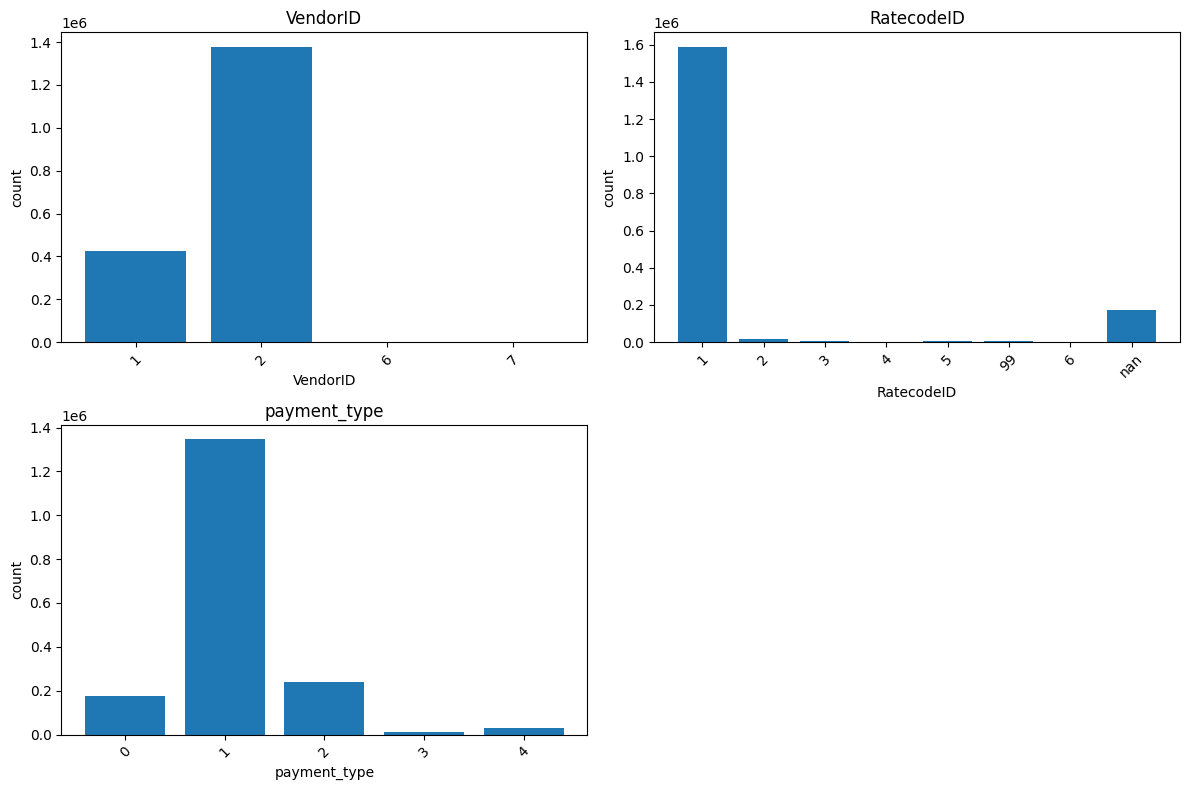

In [13]:
# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols):
    if DATA_SUBSET == "test":
        return None  # Skip plotting when using test data

    rows = ceildiv(n, cols)  # Compute required number of rows
    figsize = (6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)  # Create subplot grid

    for i, ax in enumerate(axes.flatten()):
        if i >= n:
            fig.delaxes(ax)  # Remove unused subplots
            continue

        yield i, ax

    plt.tight_layout()
    plot(figsize=figsize)


# label the cateogricals
raw_categorical = [
    "VendorID",
    "RatecodeID",
    "payment_type",
]

# Plot the categoricals to assess distribution

for i, ax in nplots(len(raw_categorical), 2):
    feature = raw_categorical[i]

    counts = rides[feature].value_counts(dropna=False).sort_index()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")
    ax.tick_params(axis="x", rotation=45)

Plot the raw numerical data to assess distributions

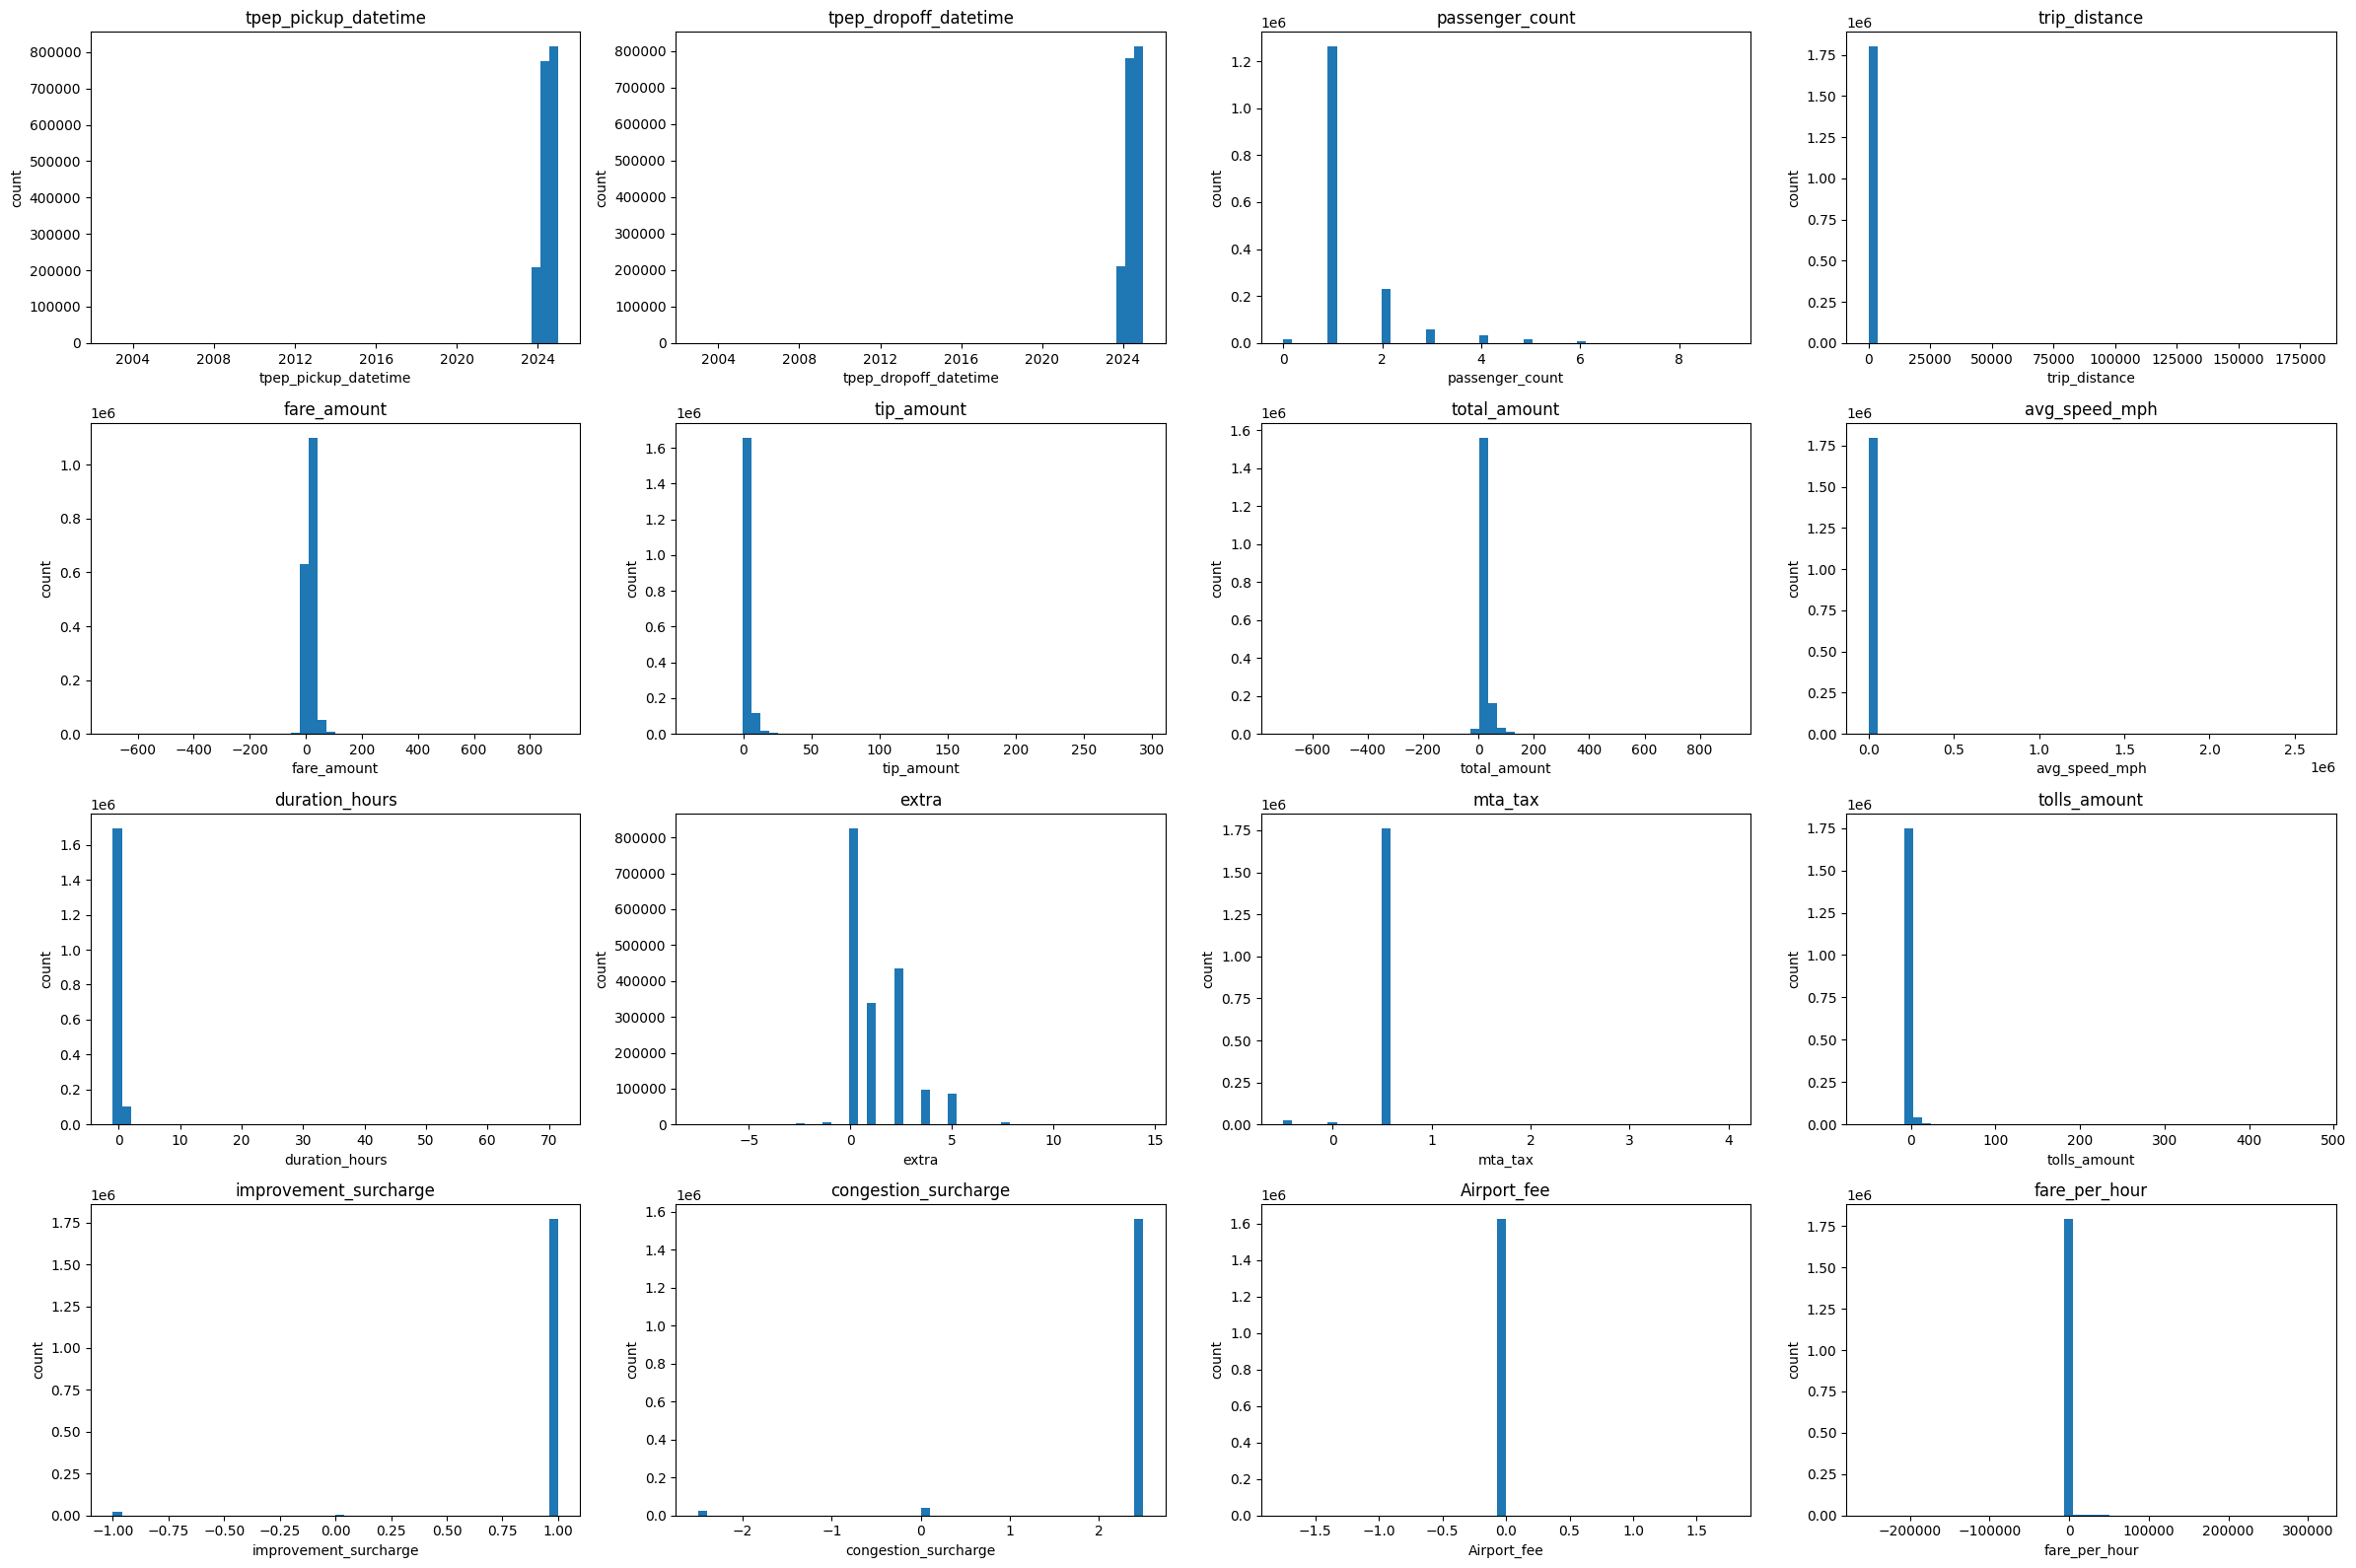

In [14]:
raw_numeric = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "avg_speed_mph",
    "duration_hours",
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "Airport_fee",
    "fare_per_hour",
]

# Construct some binned histograms of the numerical variables so we can see the distribution and observe outliers.

for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(rides[feature].dropna(), bins=50)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")


Same but with log scale

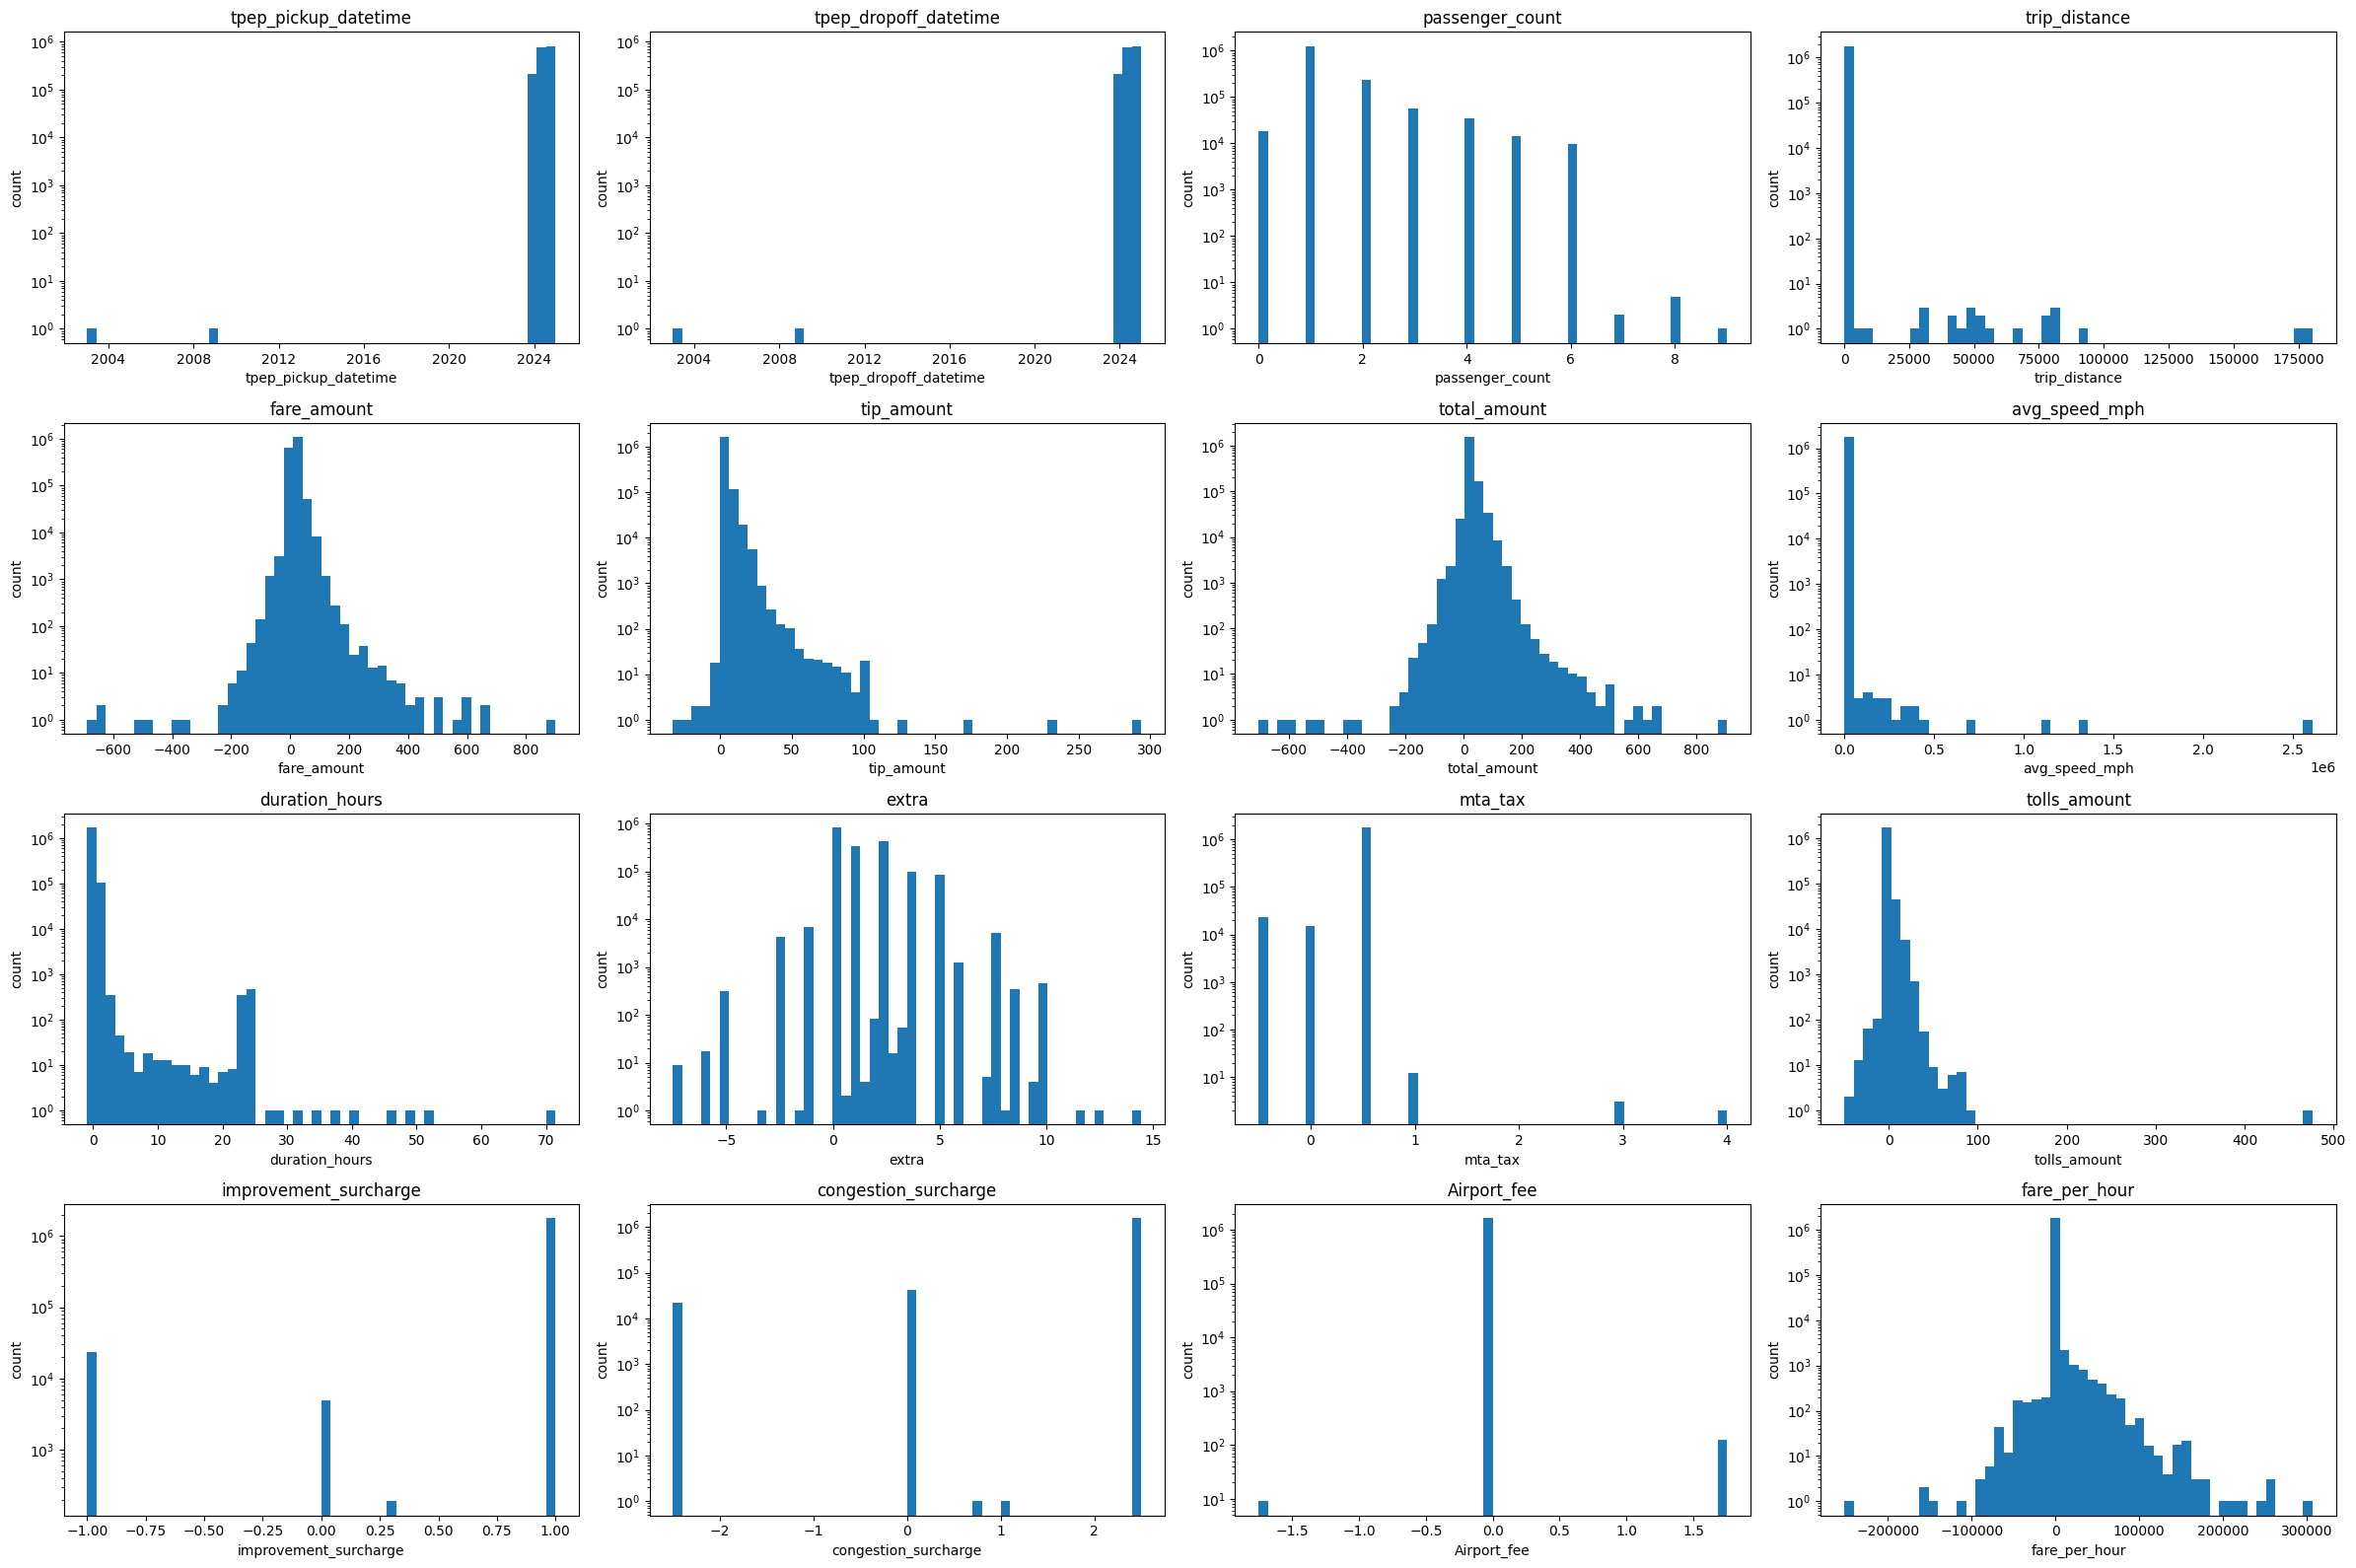

In [15]:
for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(rides[feature].dropna(), bins=50, log=True)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")

In [16]:
# Based on the above, we want to investigate trip_distance, fare_amount, mta_tax, total_amount, duration_hours, avg_speed_mph

# All negative values must be removed.

# Need to determine cut-off points for the others, to prevent enormous outliers from biasing the models.
# Below, we try some potential cut-offs and oberve the tails

print("Counts of extreme / invalid values:\n")

# Tune the below checks to see how data is distributed at the tails
# Can add new features to the below checks and change the cut-offs as per requirement.
# During analysis, these have been changed extensively.
checks = {
    "total_amount > 1000"  : ("total_amount"  , lambda x: x >  1000),
    "total_amount < 0.0"   : ("total_amount"  , lambda x: x <= 0.0),
    "avg_speed_mph > 150"  : ("avg_speed_mph" , lambda x: x >  150),
    "avg_speed_mph < 1"    : ("avg_speed_mph" , lambda x: x <  1),
    "duration_hours > 12"  : ("duration_hours", lambda x: x >  12),
    "duration_hours < 0.01": ("duration_hours", lambda x: x <  0.01),
}

for name, (col, condition) in checks.items():
    full_col = rides[col]
    flagged = full_col[condition(full_col)]
    count = len(flagged)

    if count > 0:
        # quantile position in the FULL distribution
        q_low = (full_col <= flagged.min()).mean()
        q_high = (full_col <= flagged.max()).mean()

        print(
            f"{name}: {count} | "
            f"value range: {flagged.min():.4f} to {flagged.max():.4f} | "
            f"full-sample quantile range: {q_low:.4f} to {q_high:.4f}"
        )
    else:
        print(f"{name}: {count}")

Counts of extreme / invalid values:

total_amount > 1000: 0
total_amount < 0.0: 23899 | value range: -704.1800 to 0.0000 | full-sample quantile range: 0.0000 to 0.0133
avg_speed_mph > 150: 258 | value range: 152.7273 to 2611641.0000 | full-sample quantile range: 0.9996 to 0.9997
avg_speed_mph < 1: 31493 | value range: 0.0000 to 0.9995 | full-sample quantile range: 0.0152 to 0.0175
duration_hours > 12: 870 | value range: 12.0861 to 71.4786 | full-sample quantile range: 0.9995 to 1.0000
duration_hours < 0.01: 12526 | value range: -0.9206 to 0.0097 | full-sample quantile range: 0.0000 to 0.0070


In [17]:
# Investigate some of the values that should be fixed according to TLC Taxis

print(rides["improvement_surcharge"].value_counts(dropna=False))
print("\n")
print(rides["congestion_surcharge"].value_counts(dropna=False))

improvement_surcharge
 1.0    1771212
-1.0      23631
 0.0       4966
 0.3        191
Name: count, dtype: int64


congestion_surcharge
 2.50    1561443
 NaN      174144
 0.00      41725
-2.50      22686
 1.00          1
 0.75          1
Name: count, dtype: int64


In [18]:
def get_constraint_violations(df, pad=1):

    violations = {}
    # These are the cut-offs we apply to the data. They are decided and refined using statistical assessment above.
    # The conditions describe what data will be flagged
    # Reasonable upper bounds are determined based on analysis of the tails of the data - as above and below.
    possible_checks = {
        'passenger_count': lambda x: x < 0,
        'trip_distance': lambda x: (x <= 0) | (x > 40 * pad), # to ensure the taxi actually moved
        'fare_amount': lambda x: (x < 0) | (x > 100 * pad), # Cannot be negative, reasonable upper bound.
        'fare_per_hour': lambda x: (x < 0) | (x > 1000 * pad), # Cannot be negative, reasonable upper bound.
        'extra': lambda x: x < 0, # Cannot be negative
        'mta_tax': lambda x: (x < 0) | (x > 1 * pad), # MTA is supposed to be $0.5, but accounting for small variance
        'tip_amount': lambda x: (x < 0) | (x > 40 * pad), # Reasonable upper bound
        'tolls_amount': lambda x: (x < 0) | (x > 40 * pad), # Reasonable upper bound
        'improvement_surcharge': lambda x: x != 1.0, # Improv surcharge must be $1 as per TLC Taxi website
        'total_amount': lambda x: (x < 4.00) | (x > 250 * pad), # Minimum cost is $4 due to improv surcharge ($1) and min fee ($3). Reasonable upper bound
        'congestion_surcharge': lambda x: x.notna() & (x != 0) & (x != 2.5), # Must be 0 or $2.5 as per TLC Taxi website. Accept NaNs - benefit of doubt.
        'Airport_fee': lambda x: x < 0,
        'duration_hours': lambda x: (x < 0.01) | (x > 2 * pad), # to remove any entries which took zero time
        'avg_speed_mph': lambda x: (x <= 0) | (x > 40 * pad), # to remove any entries which suggest the taxi has moved unrealistically far in a given time.
        'tpep_pickup_datetime': lambda x: (x < "2024-01-01") | (x >= "2025-01-01")
    }

    # Column-based checks
    for col, condition in possible_checks.items():
        if col in df.columns:
            mask = condition(df[col])
            violations[col] = df.index[mask].tolist()

    # Datetime check. Ensure dates make sense.
    if 'tpep_pickup_datetime' in df.columns and 'tpep_dropoff_datetime' in df.columns:
        mask = df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']
        violations['pickup_before_dropoff'] = df.index[mask].tolist()

    # Combine all violating indices
    all_bad_indices = set()
    for v in violations.values():
        all_bad_indices.update(v)

    return violations, all_bad_indices

# ##

# clean the dataset for real now

# Get the violation df and the row numbers of offending data entries
violations, bad_idx = get_constraint_violations(rides)
rides_clean = rides.drop(index=bad_idx)

# Print a summary in order to check how much is flagged. We want this to be relatively small compared to sample size.
pad = max(len(v) for v in violations.keys())
print(f"{"violation":<{pad + 1}}count")
for k, v in violations.items():
    print(f"{k:<{pad + 1}}{len(v)}")
print(f"Total bad rows: {len(bad_idx)}")
print(f"Ratio bad rows: {len(bad_idx) / len(rides)}")

violation             count
passenger_count       0
trip_distance         27869
fare_amount           31453
fare_per_hour         37733
extra                 11563
mta_tax               23043
tip_amount            344
tolls_amount          745
improvement_surcharge 28788
total_amount          29906
congestion_surcharge  22688
Airport_fee           9
duration_hours        13838
avg_speed_mph         28958
tpep_pickup_datetime  3
pickup_before_dropoff 70
Total bad rows: 67518
Ratio bad rows: 0.03751


Total bad rows: 63588
Ratio bad rows: 0.035326666666666666


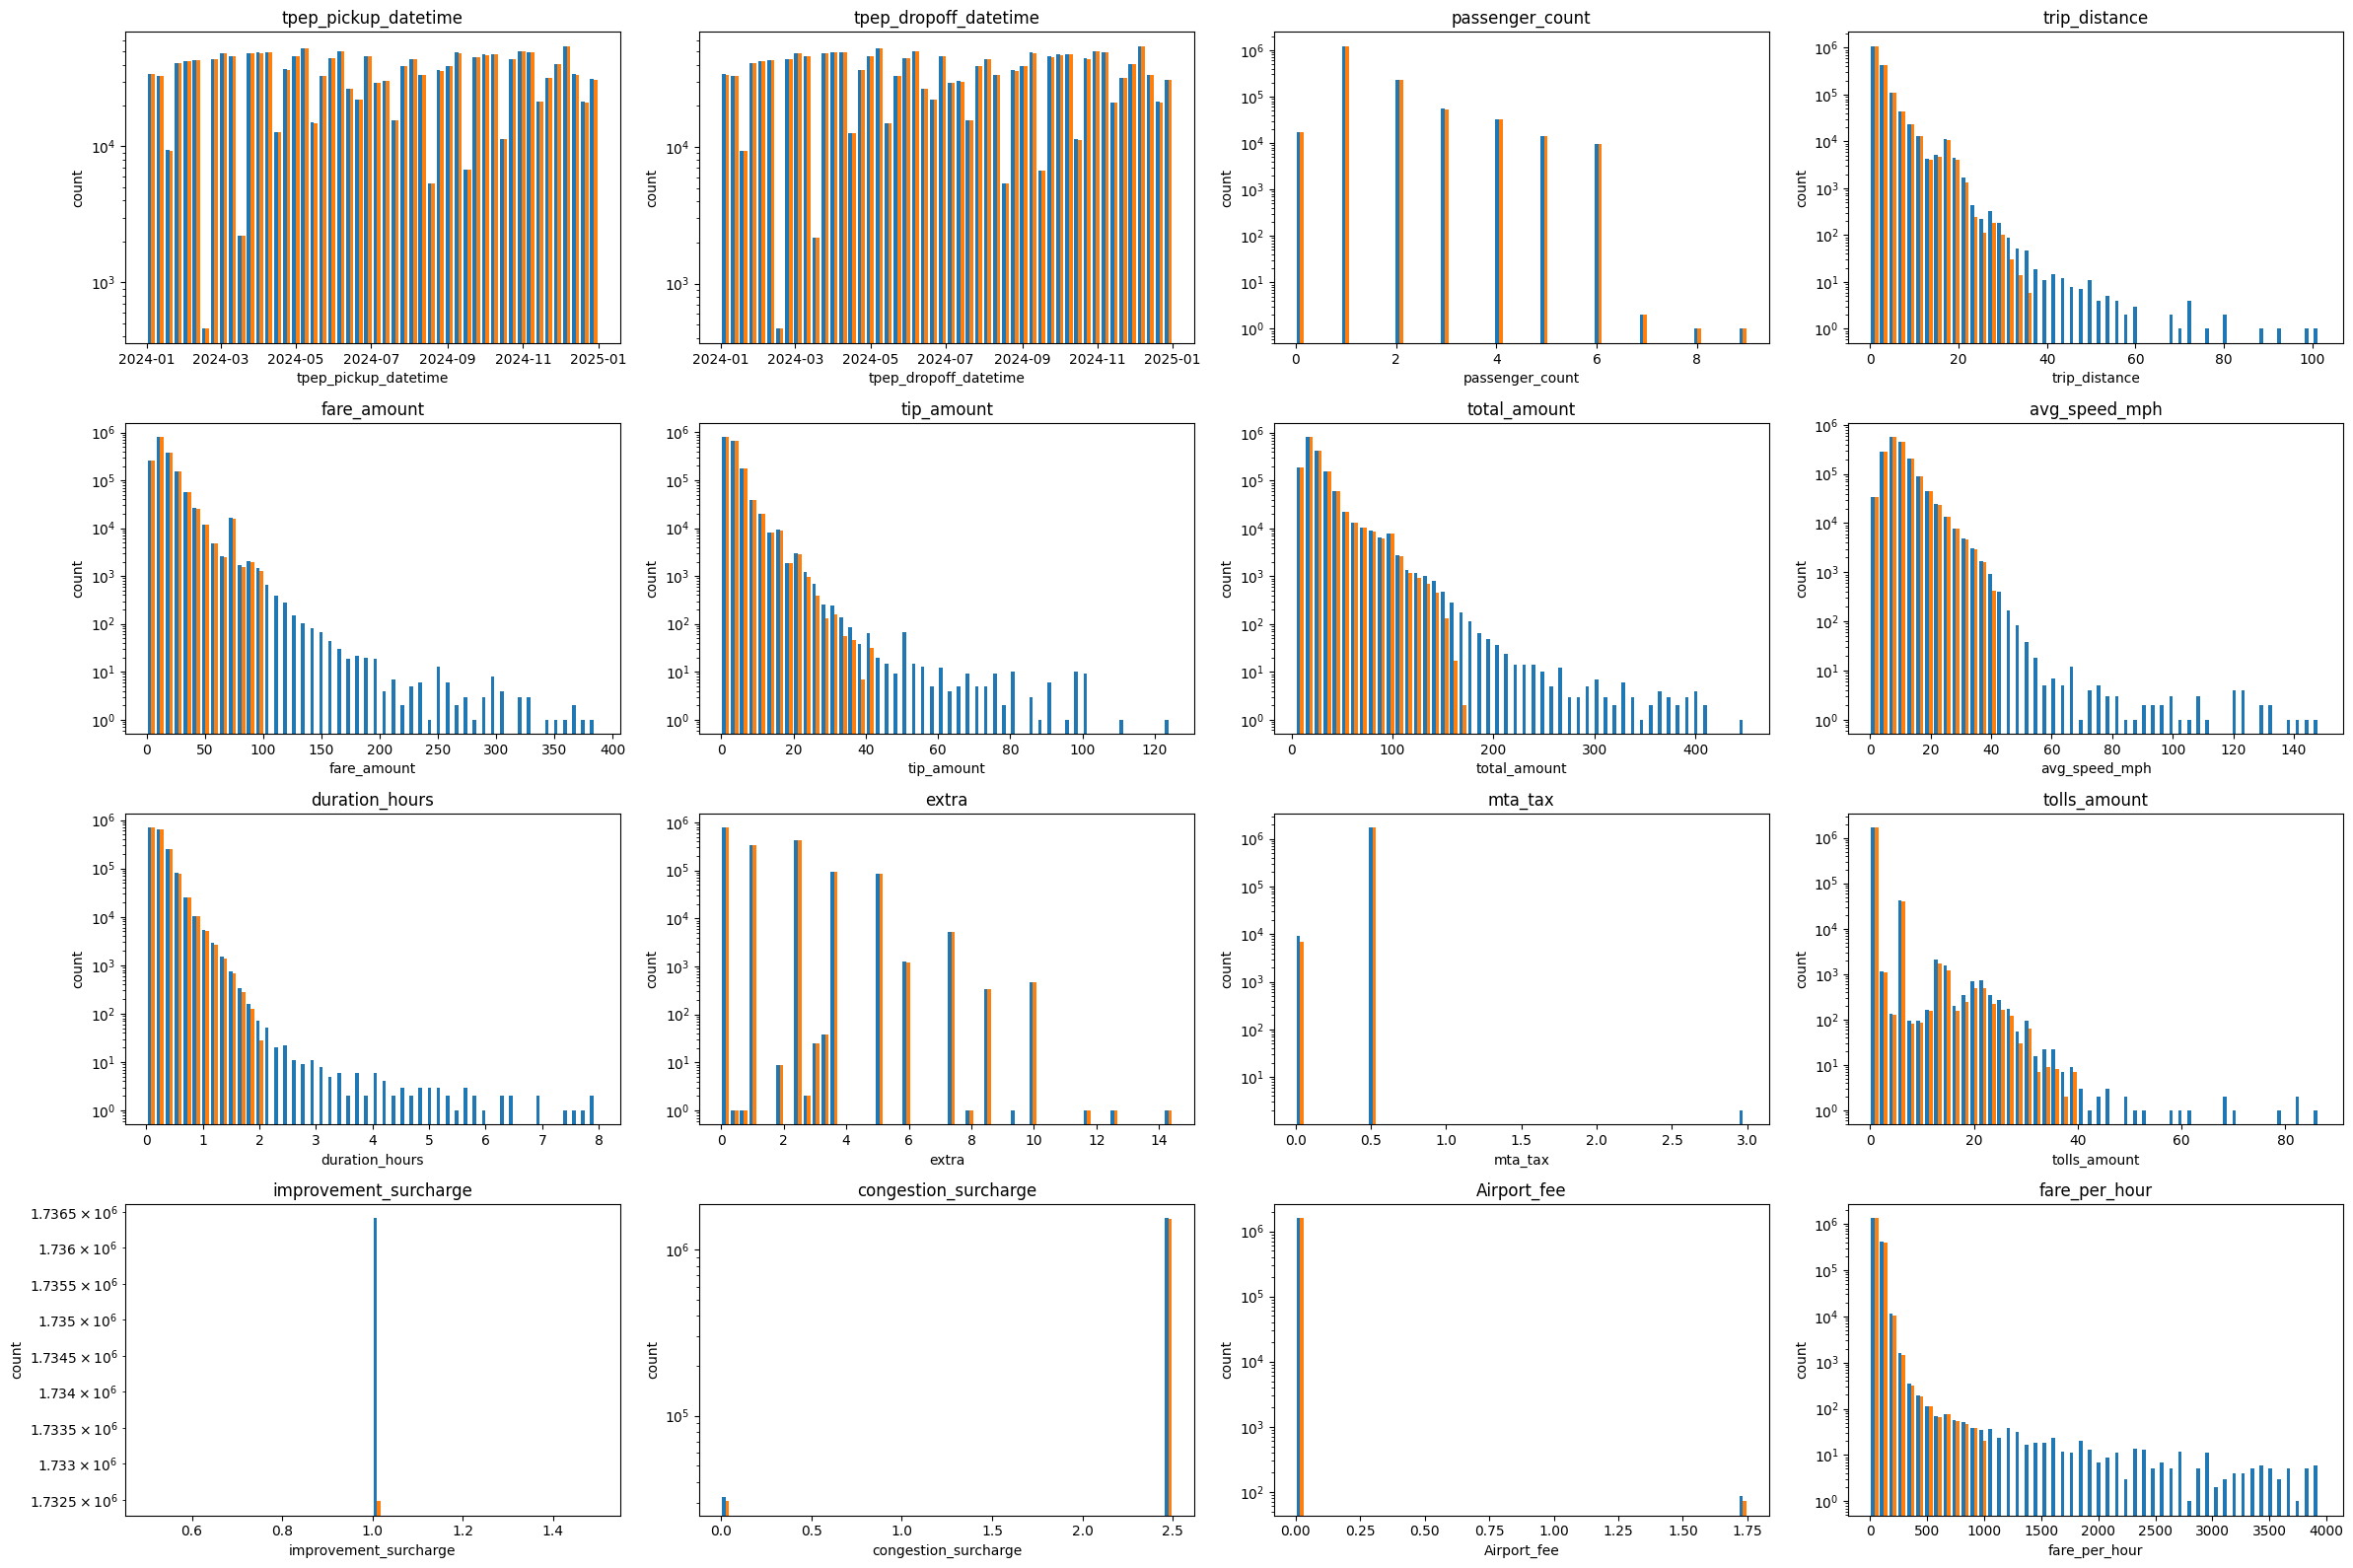

In [19]:
# plot with padding to see the edges of what's being removed
# pad multiplies upper bound of gamma-distributed variables by 4

_, bad_idx_pad = get_constraint_violations(rides, pad=4)
print(f"Total bad rows: {len(bad_idx_pad)}")
print(f"Ratio bad rows: {len(bad_idx_pad) / len(rides)}")
rides_pad = rides.drop(index=bad_idx_pad)

# Make plots
for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(
        [
            rides_pad[feature].dropna(),
            rides_clean[feature].dropna(),
        ],
        label=["upper bound x4", "upper bound"],
        bins=50, # Empirically enough to show trends
        log=True,
    )
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")

Note: the above graphs are quite small, but this is acceptable as they are only meant to highlight the tails that have been removed.

The above graph looks extreme, but it is in log scale. In a linear scale
it looks more appropriate. More dat is often better, but these variables
have very long tails which can throw off mechanisms like scaling and makes
learning correlations difficult.

Future work would be to try to non-linearly compress the outlying values
instead of throwing them out entirely.

All things considered, the discarded data is < 5% of the training data. This is quite a small amount, so we are satisfied that the value of the the data is not diminished, but a number of unrealistic data points have been removed.

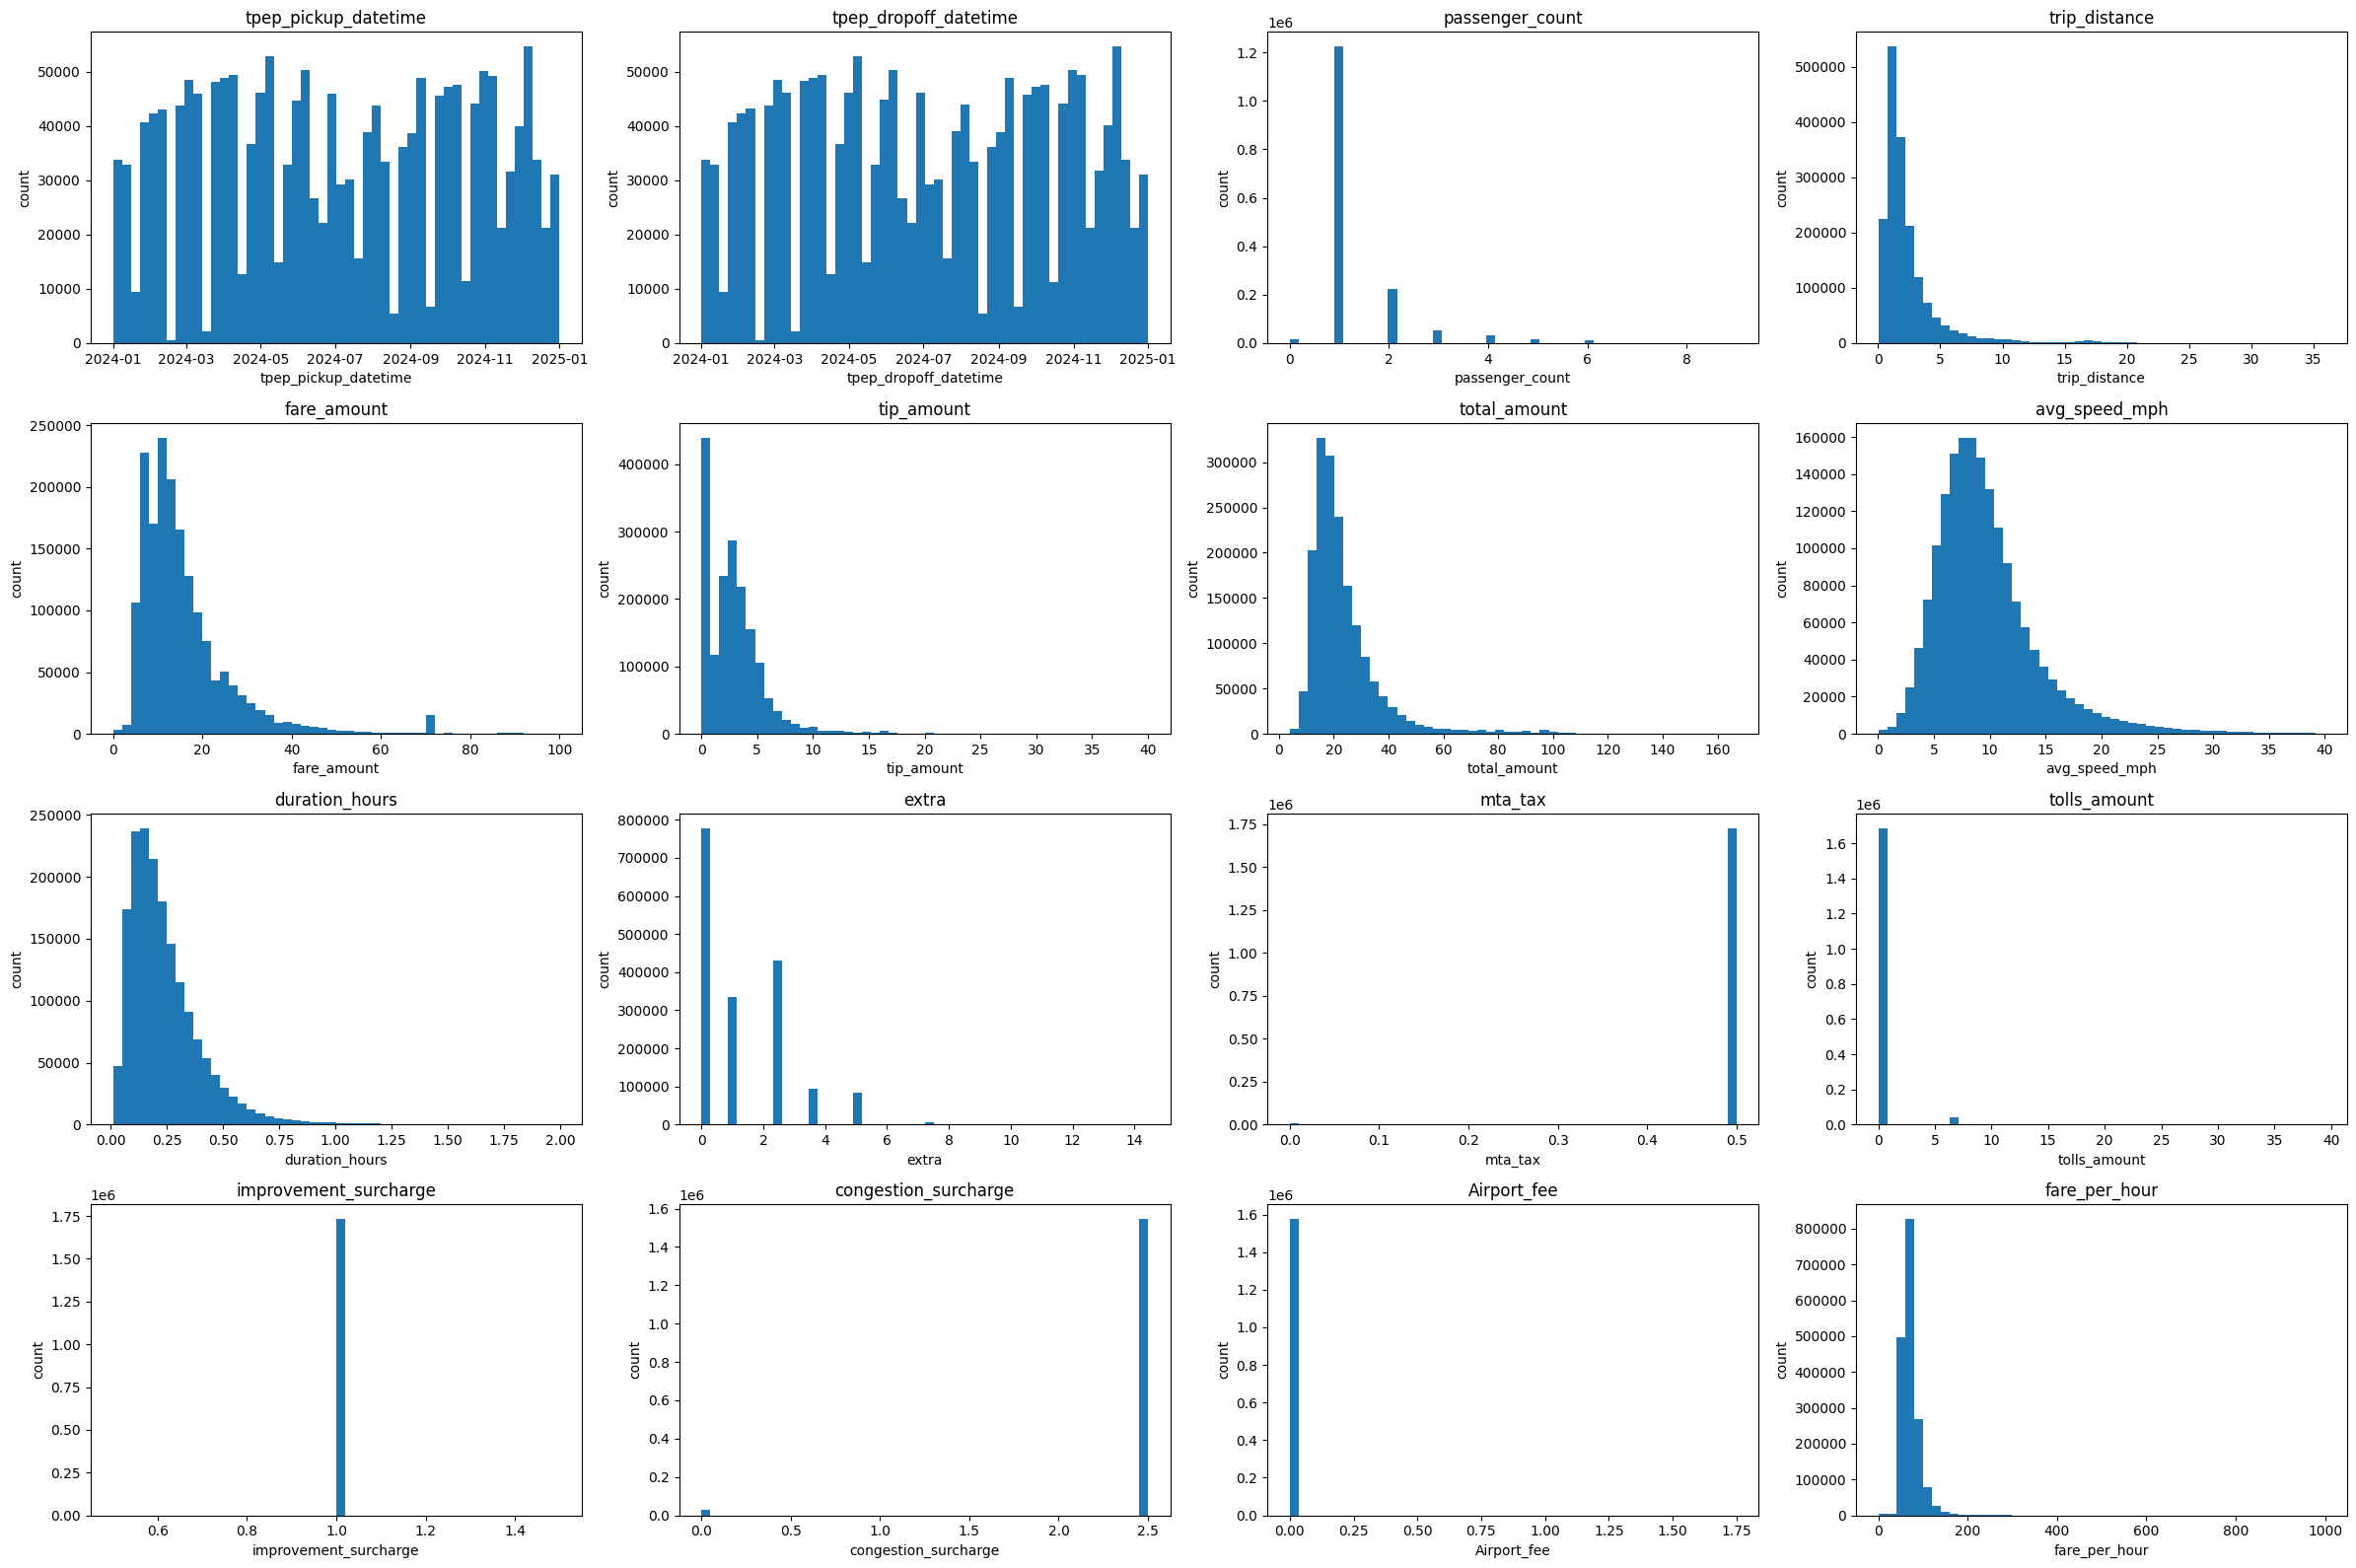

In [20]:
for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(rides_clean[feature].dropna(), bins=50)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")

In [21]:
# Check dimensions of the cleaned set.
rides_clean.dtypes
rides_clean.shape

(1732482, 22)

In [22]:
# Save the cleaned data for later use.

def save_split(df, prefix, rows_per_file=1800000):
    for i in range(0, ceildiv(len(df), rows_per_file)):
        df[i*rows_per_file:(i+1)*rows_per_file].to_csv(dbg(f"{prefix}_{i:02}.csv"), index=False)

save_split(
    rides_clean.sort_values("tpep_pickup_datetime"),
    f"../dataset-clean/{DATA_SUBSET}",
)

../dataset-clean/sample_00.csv


OSError: Cannot save file into a non-existent directory: '..\dataset-clean'